# RoboMemArena-RI: Clean Success and Perturbed Failure

This notebook presents recorded failures under ten perturbation types. Each FS+Mod case is paired with a clean success using the same task, seed, and initial scene hash.

**Scope.** These historical Arena recordings illustrate the ten event families. Their displacement, timing, and duration can differ from supplementary Table 2. They are selected qualitative examples, not measurements under the submission defaults or estimates of population success rates.

The clean video appears on the left and the perturbed failure on the right. Comparison images and metrics are embedded; videos use relative paths into `appendix_videos`.

In [1]:
from pathlib import Path
import hashlib
import json
from IPython.display import display, Image, HTML, Markdown

ROOT = Path.cwd()
if not (ROOT / "appendix_videos/manifest.json").exists():
    ROOT = ROOT / "robustness_arena_test/submit_codes"
gallery = json.loads((ROOT / "appendix_videos/manifest.json").read_text())
cases = gallery["cases"]
assert len(cases) == 10
for case in cases:
    directory = ROOT / "appendix_videos" / Path(case["failure_video"]).parent
    clean = json.loads((directory / "clean_result.json").read_text())
    failure = json.loads((directory / "failure_result.json").read_text())
    assert clean["tsr"] == 1 and failure["tsr"] == 0
    assert clean["task"] == failure["task"] and clean["seed"] == failure["seed"]
    assert clean["init_state_sha1"] == failure["init_state_sha1"]
    for role in ("failure", "clean"):
        video = ROOT / "appendix_videos" / case[f"{role}_video"]
        assert hashlib.sha256(video.read_bytes()).hexdigest() == case[f"{role}_sha256"]
print("Verified ten clean-success / perturbed-failure pairs, matching initial scenes and video SHA-256 hashes.")

Verified ten clean-success / perturbed-failure pairs, matching initial scenes and video SHA-256 hashes.


## Conditions and Reporting

`robo_ri/protocol.py` defines four task-object perturbations and six distractor events. Clean is a separate control. Late-arrival variants are excluded.

The seven baselines are FS+Mod, SimpleMemVLA, TraceFlow, MemER, PrediMem, FS+Mod (Retrieval), and pi0.5. The paper's Arena RI-Mem variants use FS+Mod and SimpleMemVLA.

Success rates use a task macro-average. Coverage, invalid events, technical errors, and missing episodes are reported separately. Timing comparisons require both paired episodes to succeed with the same initial scene hash.

In [2]:
from robo_ri.protocol import CONDITIONS, METHODS
rows = "".join(f"<tr><td>{name}</td><td>{c.family}</td><td>{', '.join(c.variants)}</td></tr>" for name, c in CONDITIONS.items())
display(HTML("<table><tr><th>Condition</th><th>Family</th><th>Variants</th></tr>" + rows + "</table>"))
print("Registered methods:", ", ".join(METHODS))

Condition,Family,Variants
onset_arrival,onset_arrival,default
mid_arrival,mid_arrival,default
mid_shift,displacement,default
remove_return,displacement,default
tv_on,distractor,default
object_passby,distractor,default
unrelated_object,distractor,"insert, remove"
target_like_object,distractor,"insert, remove"
camera_shake,distractor,default
light_change,distractor,"bright, dark"


Registered methods: fs_mod, simplememvla, traceflow, memer, predimem, fs_mod_retrieval, pi05, fs_mod_ri, simplememvla_ri


## Shared RI-Mem Readout

SCQ encodes the active subgoal and evidence requirements as a six-dimensional query. AMR uses relevance, explicit irrelevance, observability, and temporal validity to produce bounded historical-key biases and a shared gate. Only $W\in\mathbb{R}^{6\times5}$ and $\beta\in\mathbb{R}^{5}$ are trainable: 35 parameters in total.

FS+Mod adds biases to dedicated memory attention and gates its output. SimpleMemVLA applies biases and $\log g$ to historical video keys in full-attention layers 27 and 31. Both preserve native memory selection and action prediction. The following numerical check is not a task evaluation.

In [3]:
import numpy as np
from robo_ri.ri_mem.head import initial_parameters, numpy_priors
p = initial_parameters()
query = np.array([1, 1, 0, 0, 1, 1], np.float32)
features = np.array([[.9, 0, .8, -1], [0, .9, 0, 0], [.9, 0, 0, 1]], np.float32)
bias, gate = numpy_priors(p, query, features)
assert sum(value.size for value in p.values()) == 35
assert (np.abs(bias) <= .6).all() and .92 <= gate <= 1.08
print("Example key biases:", bias.round(4).tolist(), "gate:", round(float(gate), 4))

Example key biases: [-0.1242, -0.5991, 0.4746] gate: 0.9968


## 01. onset_arrival — Task 9, seed 52

Put butter into the frypan, pour tomato sauce over it twice, then place the sauce bottle into the bowl drainer.

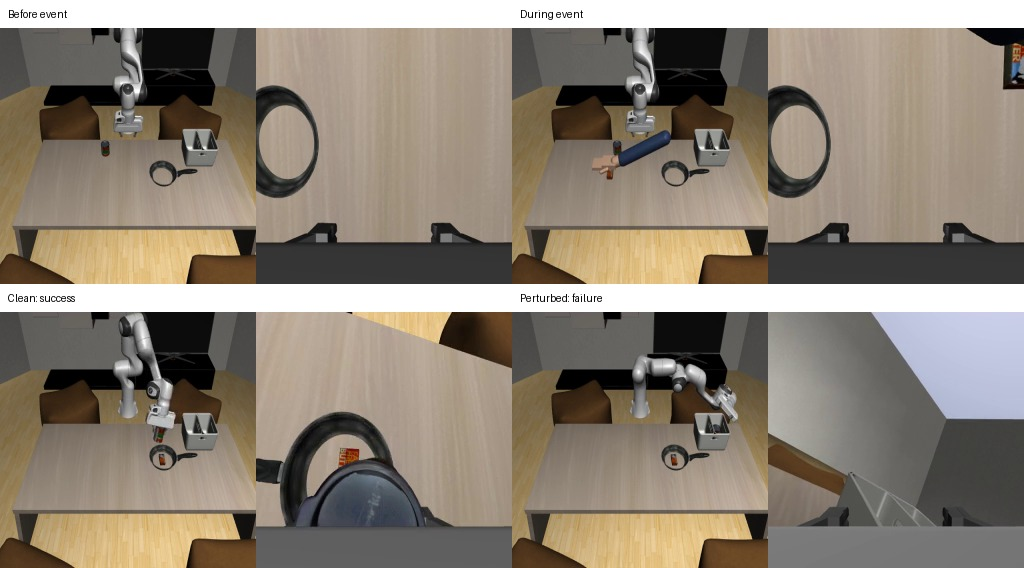

Incomplete native stages: 03_Pour_Two
Source condition: onset_sync | Event video frames: [87, 144]
Paper-default parameter match: False | Protocol: v4.1+tr-v1


In [4]:
case = cases[0]
display(Markdown(f"## {case['number']:02d}. {case['condition']} — Task {case['task']}, seed {case['seed']}"))
display(Markdown(case["prompt"]))
display(Image(filename=str(ROOT / "appendix_videos" / case["comparison"])))
clean_url = "appendix_videos/" + case["clean_video"]
failure_url = "appendix_videos/" + case["failure_video"]
display(HTML(f'<video controls preload="none" width="49%" src="{clean_url}"></video> <video controls preload="none" width="49%" src="{failure_url}"></video>'))
print("Incomplete native stages:", ", ".join(case["incomplete_stages"]))
print("Source condition:", case["original_condition"], "| Event video frames:", case["video_event_frame_range"])
print("Paper-default parameter match:", case["paper_parameter_match"], "| Protocol:", case["source_protocol"])


## 02. mid_arrival — Task 21, seed 51

Put butter into the microwave and then put chocolate into the location where the butter was placed.

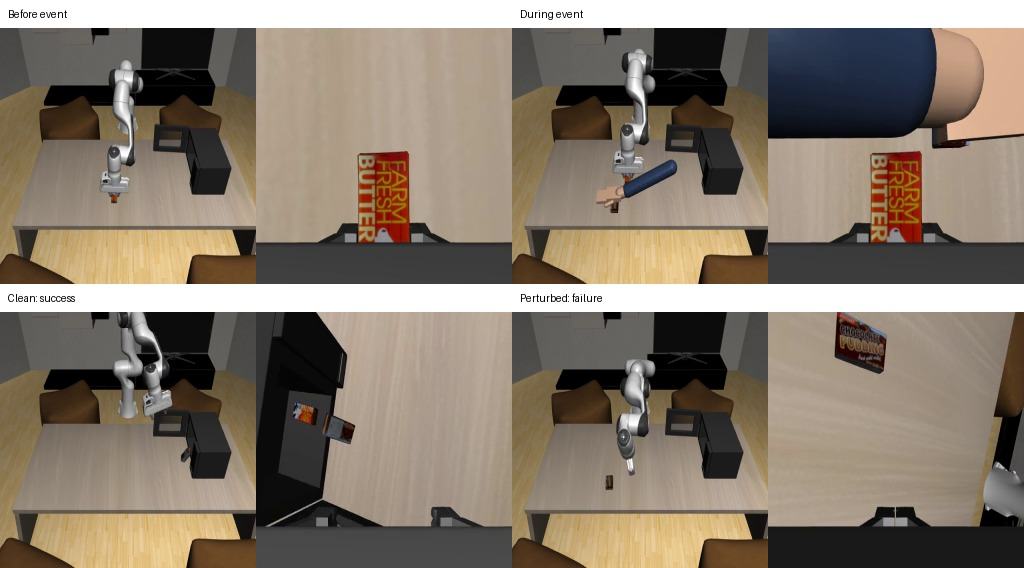

Incomplete native stages: 03_Place_Chocolate_Microwave
Source condition: arrive_early | Event video frames: [225, 298]
Paper-default parameter match: False | Protocol: v4.1+tr-v1


In [5]:
case = cases[1]
display(Markdown(f"## {case['number']:02d}. {case['condition']} — Task {case['task']}, seed {case['seed']}"))
display(Markdown(case["prompt"]))
display(Image(filename=str(ROOT / "appendix_videos" / case["comparison"])))
clean_url = "appendix_videos/" + case["clean_video"]
failure_url = "appendix_videos/" + case["failure_video"]
display(HTML(f'<video controls preload="none" width="49%" src="{clean_url}"></video> <video controls preload="none" width="49%" src="{failure_url}"></video>'))
print("Incomplete native stages:", ", ".join(case["incomplete_stages"]))
print("Source condition:", case["original_condition"], "| Event video frames:", case["video_event_frame_range"])
print("Paper-default parameter match:", case["paper_parameter_match"], "| Protocol:", case["source_protocol"])


## 03. mid_shift — Task 21, seed 51

Put butter into the microwave and then put chocolate into the location where the butter was placed.

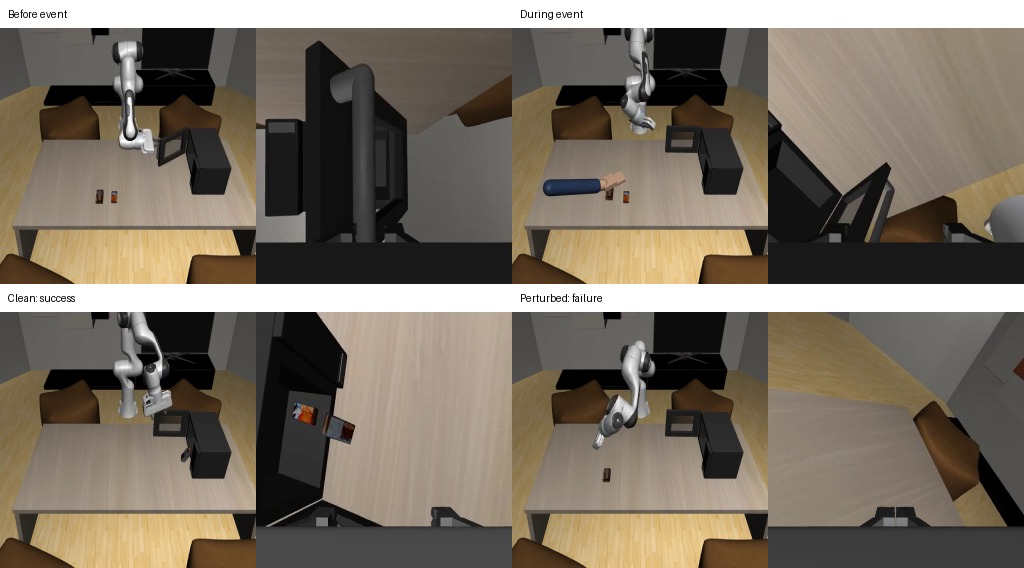

Incomplete native stages: 03_Place_Chocolate_Microwave
Source condition: displace | Event video frames: [112, 175]
Paper-default parameter match: False | Protocol: v4.1+tr-v1


In [6]:
case = cases[2]
display(Markdown(f"## {case['number']:02d}. {case['condition']} — Task {case['task']}, seed {case['seed']}"))
display(Markdown(case["prompt"]))
display(Image(filename=str(ROOT / "appendix_videos" / case["comparison"])))
clean_url = "appendix_videos/" + case["clean_video"]
failure_url = "appendix_videos/" + case["failure_video"]
display(HTML(f'<video controls preload="none" width="49%" src="{clean_url}"></video> <video controls preload="none" width="49%" src="{failure_url}"></video>'))
print("Incomplete native stages:", ", ".join(case["incomplete_stages"]))
print("Source condition:", case["original_condition"], "| Event video frames:", case["video_event_frame_range"])
print("Paper-default parameter match:", case["paper_parameter_match"], "| Protocol:", case["source_protocol"])


## 04. remove_return — Task 9, seed 52

Put butter into the frypan, pour tomato sauce over it twice, then place the sauce bottle into the bowl drainer.

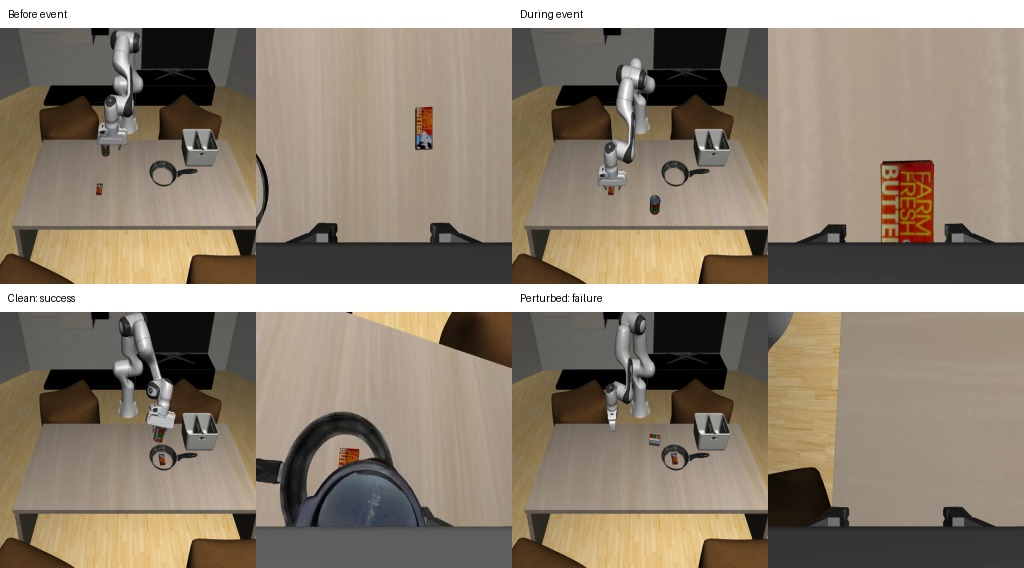

Incomplete native stages: 03_Pour_Two
Source condition: takeback_early | Event video frames: [21, 242]
Paper-default parameter match: False | Protocol: v4.1+tr-v2


In [7]:
case = cases[3]
display(Markdown(f"## {case['number']:02d}. {case['condition']} — Task {case['task']}, seed {case['seed']}"))
display(Markdown(case["prompt"]))
display(Image(filename=str(ROOT / "appendix_videos" / case["comparison"])))
clean_url = "appendix_videos/" + case["clean_video"]
failure_url = "appendix_videos/" + case["failure_video"]
display(HTML(f'<video controls preload="none" width="49%" src="{clean_url}"></video> <video controls preload="none" width="49%" src="{failure_url}"></video>'))
print("Incomplete native stages:", ", ".join(case["incomplete_stages"]))
print("Source condition:", case["original_condition"], "| Event video frames:", case["video_event_frame_range"])
print("Paper-default parameter match:", case["paper_parameter_match"], "| Protocol:", case["source_protocol"])


## 05. tv_on — Task 9, seed 52

Put butter into the frypan, pour tomato sauce over it twice, then place the sauce bottle into the bowl drainer.

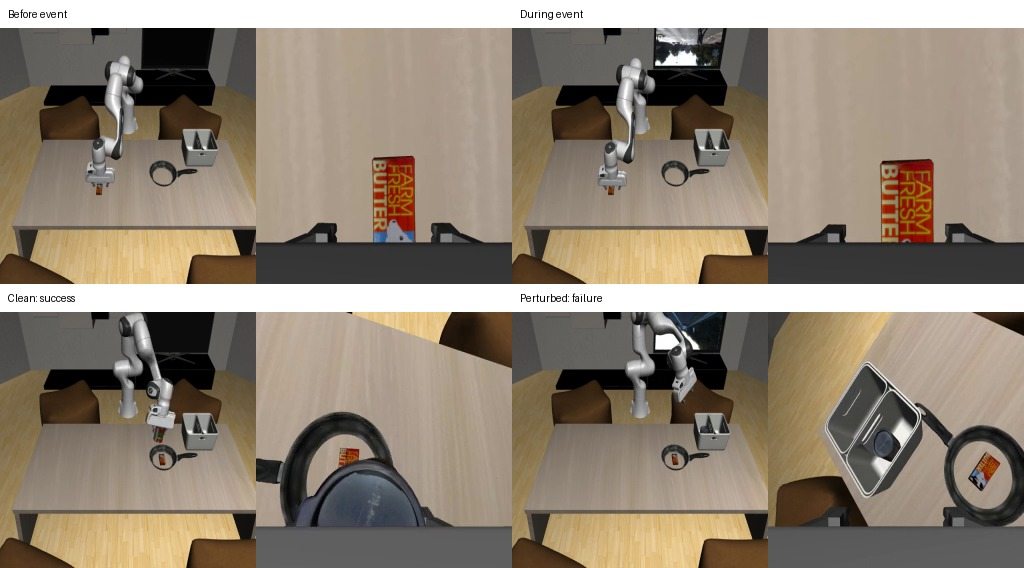

Incomplete native stages: 03_Pour_Two
Source condition: inc_tv | Event video frames: [92, 132]
Paper-default parameter match: False | Protocol: v4.1


In [8]:
case = cases[4]
display(Markdown(f"## {case['number']:02d}. {case['condition']} — Task {case['task']}, seed {case['seed']}"))
display(Markdown(case["prompt"]))
display(Image(filename=str(ROOT / "appendix_videos" / case["comparison"])))
clean_url = "appendix_videos/" + case["clean_video"]
failure_url = "appendix_videos/" + case["failure_video"]
display(HTML(f'<video controls preload="none" width="49%" src="{clean_url}"></video> <video controls preload="none" width="49%" src="{failure_url}"></video>'))
print("Incomplete native stages:", ", ".join(case["incomplete_stages"]))
print("Source condition:", case["original_condition"], "| Event video frames:", case["video_event_frame_range"])
print("Paper-default parameter match:", case["paper_parameter_match"], "| Protocol:", case["source_protocol"])


## 06. object_passby — Task 9, seed 52

Put butter into the frypan, pour tomato sauce over it twice, then place the sauce bottle into the bowl drainer.

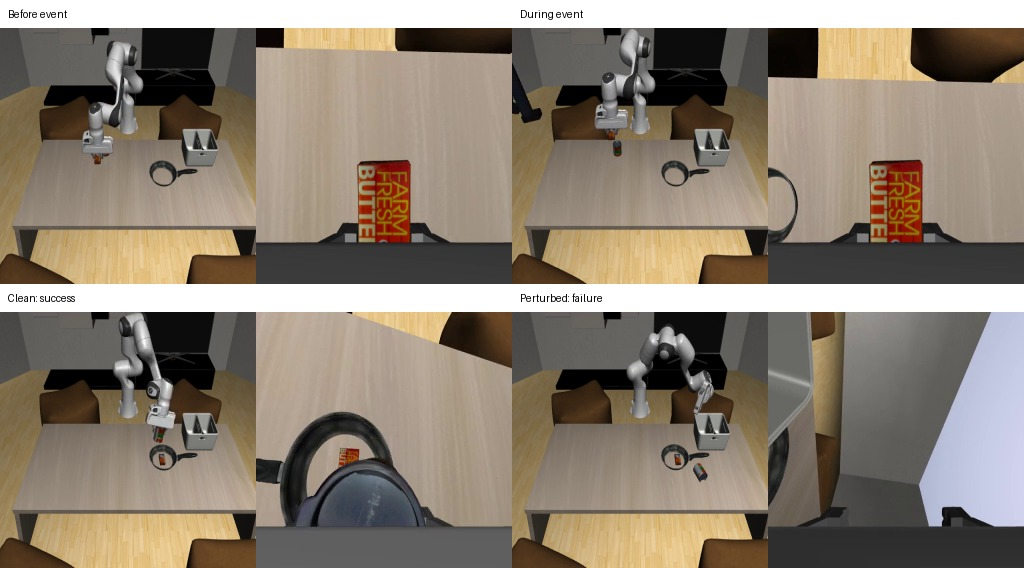

Incomplete native stages: 03_Pour_Two
Source condition: inc_passerby | Event video frames: [188, 228]
Paper-default parameter match: False | Protocol: v4.1


In [9]:
case = cases[5]
display(Markdown(f"## {case['number']:02d}. {case['condition']} — Task {case['task']}, seed {case['seed']}"))
display(Markdown(case["prompt"]))
display(Image(filename=str(ROOT / "appendix_videos" / case["comparison"])))
clean_url = "appendix_videos/" + case["clean_video"]
failure_url = "appendix_videos/" + case["failure_video"]
display(HTML(f'<video controls preload="none" width="49%" src="{clean_url}"></video> <video controls preload="none" width="49%" src="{failure_url}"></video>'))
print("Incomplete native stages:", ", ".join(case["incomplete_stages"]))
print("Source condition:", case["original_condition"], "| Event video frames:", case["video_event_frame_range"])
print("Paper-default parameter match:", case["paper_parameter_match"], "| Protocol:", case["source_protocol"])


## 07. unrelated_object — Task 4, seed 51

Open and close all drawers in order to check. Put butter into the drawer that already contains an object.

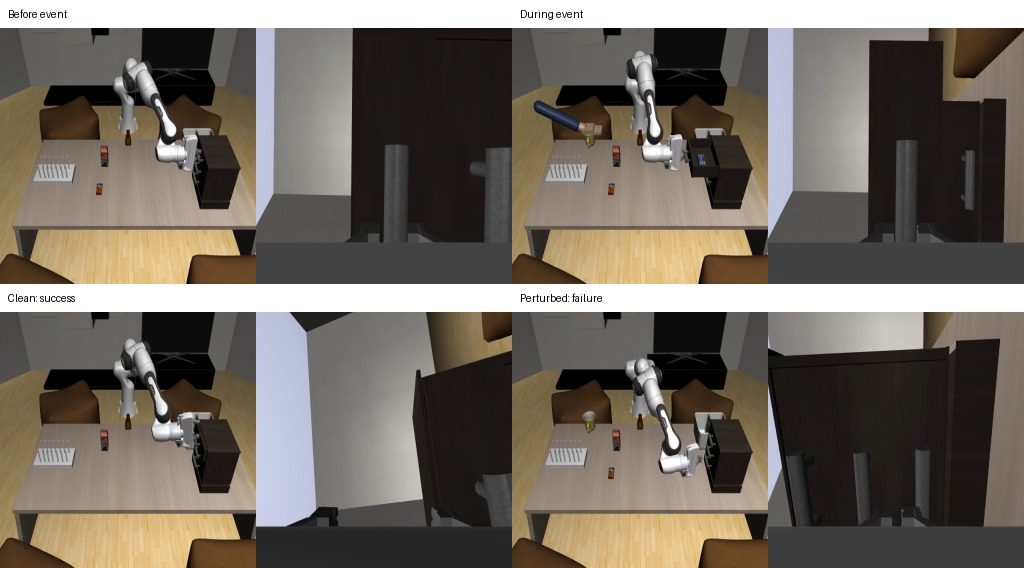

Incomplete native stages: 08_Put_Butter_Top_Drawer, 09_Close_Top_Drawer_Final
Source condition: inc_place | Event video frames: [71, 111]
Paper-default parameter match: False | Protocol: v4.1


In [10]:
case = cases[6]
display(Markdown(f"## {case['number']:02d}. {case['condition']} — Task {case['task']}, seed {case['seed']}"))
display(Markdown(case["prompt"]))
display(Image(filename=str(ROOT / "appendix_videos" / case["comparison"])))
clean_url = "appendix_videos/" + case["clean_video"]
failure_url = "appendix_videos/" + case["failure_video"]
display(HTML(f'<video controls preload="none" width="49%" src="{clean_url}"></video> <video controls preload="none" width="49%" src="{failure_url}"></video>'))
print("Incomplete native stages:", ", ".join(case["incomplete_stages"]))
print("Source condition:", case["original_condition"], "| Event video frames:", case["video_event_frame_range"])
print("Paper-default parameter match:", case["paper_parameter_match"], "| Protocol:", case["source_protocol"])


## 08. target_like_object — Task 4, seed 52

Open and close all drawers in order to check. Put butter into the drawer that already contains an object.

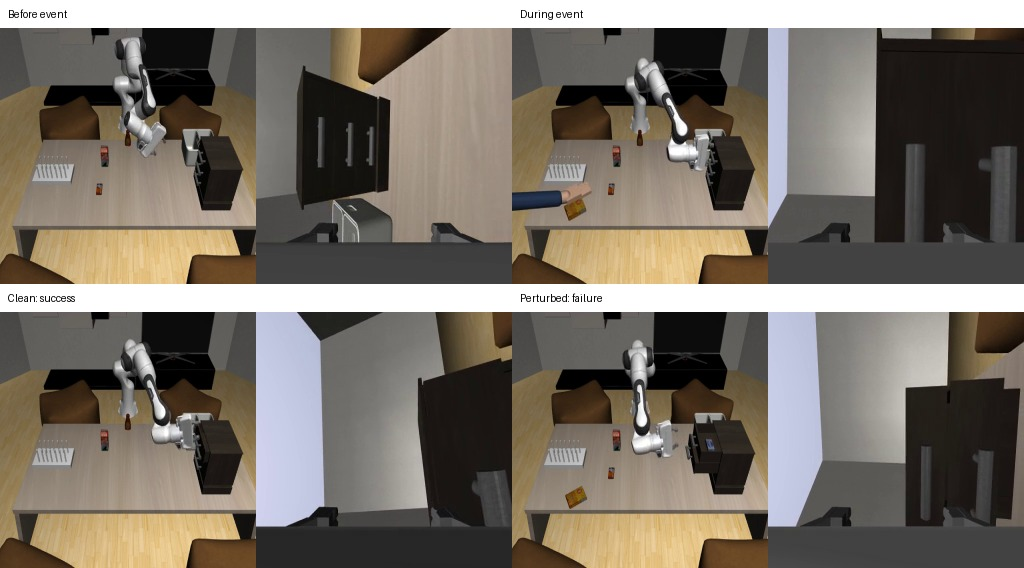

Incomplete native stages: 08_Put_Butter_Top_Drawer, 09_Close_Top_Drawer_Final
Source condition: inc_lookalike | Event video frames: [26, 66]
Paper-default parameter match: False | Protocol: v4.1


In [11]:
case = cases[7]
display(Markdown(f"## {case['number']:02d}. {case['condition']} — Task {case['task']}, seed {case['seed']}"))
display(Markdown(case["prompt"]))
display(Image(filename=str(ROOT / "appendix_videos" / case["comparison"])))
clean_url = "appendix_videos/" + case["clean_video"]
failure_url = "appendix_videos/" + case["failure_video"]
display(HTML(f'<video controls preload="none" width="49%" src="{clean_url}"></video> <video controls preload="none" width="49%" src="{failure_url}"></video>'))
print("Incomplete native stages:", ", ".join(case["incomplete_stages"]))
print("Source condition:", case["original_condition"], "| Event video frames:", case["video_event_frame_range"])
print("Paper-default parameter match:", case["paper_parameter_match"], "| Protocol:", case["source_protocol"])


## 09. camera_shake — Task 9, seed 52

Put butter into the frypan, pour tomato sauce over it twice, then place the sauce bottle into the bowl drainer.

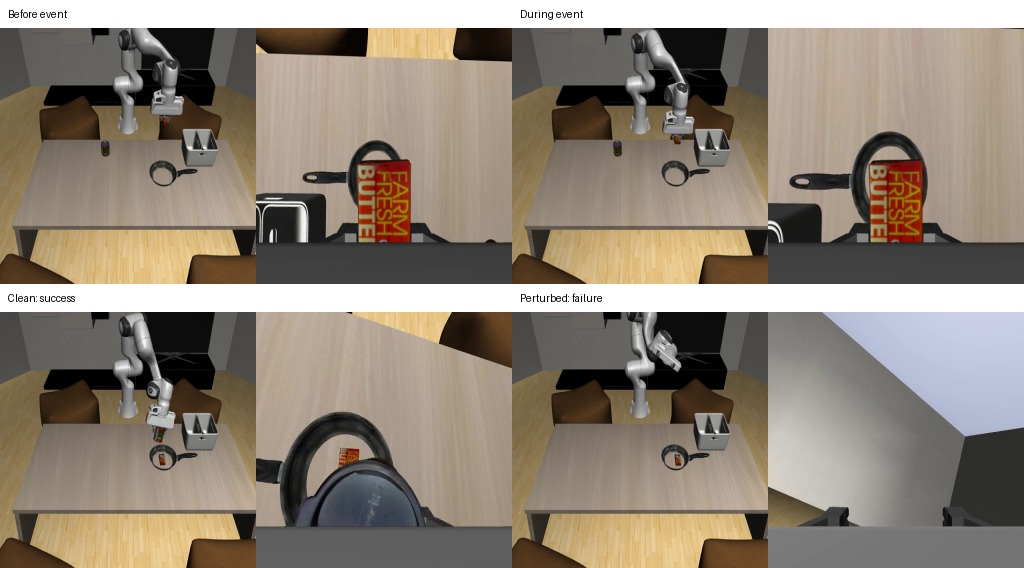

Incomplete native stages: 03_Pour_Two
Source condition: inc_camshake | Event video frames: [271, 287]
Paper-default parameter match: False | Protocol: v4.1


In [12]:
case = cases[8]
display(Markdown(f"## {case['number']:02d}. {case['condition']} — Task {case['task']}, seed {case['seed']}"))
display(Markdown(case["prompt"]))
display(Image(filename=str(ROOT / "appendix_videos" / case["comparison"])))
clean_url = "appendix_videos/" + case["clean_video"]
failure_url = "appendix_videos/" + case["failure_video"]
display(HTML(f'<video controls preload="none" width="49%" src="{clean_url}"></video> <video controls preload="none" width="49%" src="{failure_url}"></video>'))
print("Incomplete native stages:", ", ".join(case["incomplete_stages"]))
print("Source condition:", case["original_condition"], "| Event video frames:", case["video_event_frame_range"])
print("Paper-default parameter match:", case["paper_parameter_match"], "| Protocol:", case["source_protocol"])


## 10. light_change — Task 9, seed 52

Put butter into the frypan, pour tomato sauce over it twice, then place the sauce bottle into the bowl drainer.

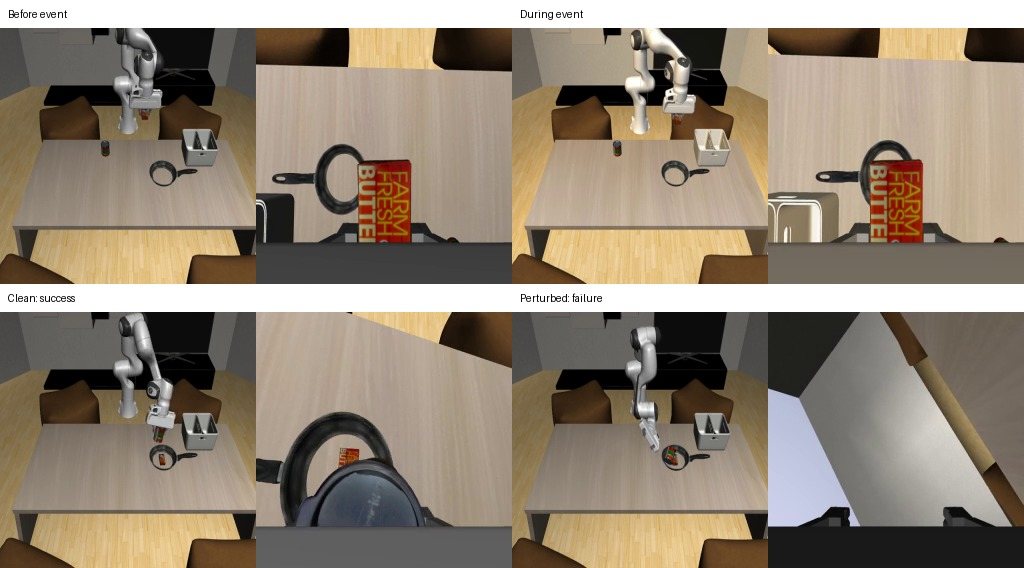

Incomplete native stages: 03_Pour_Two
Source condition: inc_light | Event video frames: [240, 280]
Paper-default parameter match: False | Protocol: v4.1


In [13]:
case = cases[9]
display(Markdown(f"## {case['number']:02d}. {case['condition']} — Task {case['task']}, seed {case['seed']}"))
display(Markdown(case["prompt"]))
display(Image(filename=str(ROOT / "appendix_videos" / case["comparison"])))
clean_url = "appendix_videos/" + case["clean_video"]
failure_url = "appendix_videos/" + case["failure_video"]
display(HTML(f'<video controls preload="none" width="49%" src="{clean_url}"></video> <video controls preload="none" width="49%" src="{failure_url}"></video>'))
print("Incomplete native stages:", ", ".join(case["incomplete_stages"]))
print("Source condition:", case["original_condition"], "| Event video frames:", case["video_event_frame_range"])
print("Paper-default parameter match:", case["paper_parameter_match"], "| Protocol:", case["source_protocol"])


## Execution and Validation Scope

Commands and environment requirements are documented in `README.md`. The evaluation workflow is `python -m robo_ri plan`, start the native backend, then `run` and `report`.

`validation` records mechanics and interface checks; `appendix_videos` contains historical measured cases. RI-Mem checkpoints require calibration on paired clean and perturbed expert training samples. Paper table entries are not treated as newly measured results.